In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import  transforms
from torch.utils.data import DataLoader , Dataset

import numpy as np
import pandas as pd

from PIL import Image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device : {device}")

Device : cuda


In [2]:
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join("..", "scripts")))
from train import run_experiment, compare_runs

EXPERIMENT_NAME = "infrared-solar-custom-cnn-binary"

d:\Computer Vision Engineer\infrared-solar\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

In [4]:
DATA_DIR = os.path.join("..", "data")

train = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
val = pd.read_csv(os.path.join(DATA_DIR, "val.csv"))
test = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))

def to_binary(df):
    df = df.copy()
    df["label_orig"] = df["label"]
    df["label"] = np.where(df["label"] == "No-Anomaly", "No-Anomaly", "Anomaly")
    return df

train, val, test = to_binary(train), to_binary(val), to_binary(test)

for name, df in [("Train", train), ("Val", val), ("Test", test)]:
    print(f"{name:5s} : {len(df):5d} | " + " | ".join(
        f"{k}: {v:.1%}" for k, v in df["label"].value_counts(normalize=True).items()))

classes = ["No-Anomaly", "Anomaly"]
label2idx = {c: i for i, c in enumerate(classes)}
idx2label = {i: c for c, i in label2idx.items()}

print(f"\n{len(classes)} classes : {label2idx}")

Train : 12780 | No-Anomaly: 50.1% | Anomaly: 49.9%
Val   :  3195 | No-Anomaly: 50.1% | Anomaly: 49.9%
Test  :  3994 | No-Anomaly: 50.1% | Anomaly: 49.9%

2 classes : {'No-Anomaly': 0, 'Anomaly': 1}


In [5]:
class CreateDataset(Dataset):
    def __init__(self, dataframe, transform=None, label2idx=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform
        self.label2idx = label2idx

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        img_path = row["filepath"]
        label = self.label2idx[row["label"]]

        image = Image.open(img_path).convert("L")

        if self.transform:
            image = self.transform(image)

        label = torch.tensor(label, dtype=torch.long)

        return image, label

In [6]:
dataset_train_with_label = CreateDataset(train, transform=train_transform, label2idx=label2idx)
dataset_val_with_label = CreateDataset(val, transform=eval_transform, label2idx=label2idx)
dataset_test_with_label = CreateDataset(test, transform=eval_transform, label2idx=label2idx)


train_with_label_loader = DataLoader(dataset_train_with_label, batch_size=32, shuffle=True)
val_with_label_loader = DataLoader(dataset_val_with_label, batch_size=64, shuffle=False)
test_with_label_loader = DataLoader(dataset_test_with_label, batch_size=64, shuffle=False)

images, labels = next(iter(train_with_label_loader))
print(images.shape, labels.shape, labels.min().item(), labels.max().item())

torch.Size([32, 1, 40, 24]) torch.Size([32]) 0 1


In [7]:
class SimpleCNN(nn.Module):
    def __init__(self, n_classes=12, in_ch=1):
        super().__init__()
        
        def block(i, o):
            return [nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                    nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                    nn.MaxPool2d(2)]

        self.features = nn.Sequential(
            *block(in_ch, 32),
            *block(32, 64),
            *block(64, 128),
        )
        self.pool = nn.AdaptiveAvgPool2d((5, 3))
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(128 * 5 * 3, n_classes))
        
    def forward(self, x):
        x = self.features(x)
        return self.head(self.pool(x).flatten(1))

model = SimpleCNN(n_classes=len(classes)).to(device)
print(model)

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): ReLU()
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1,

In [8]:
 
counts = train["label"].map(label2idx).value_counts().sort_index()
class_weights = torch.tensor(
    (len(train) / (len(classes) * counts.values)), dtype=torch.float32
).to(device)

print(pd.Series(class_weights.cpu().numpy(), index=classes).round(3))

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = optim.Adam(model.parameters(), lr=0.001)

No-Anomaly    0.999
Anomaly       1.001
dtype: float32


In [9]:
result = run_experiment(
    model, criterion, optimizer,
    train_with_label_loader, val_with_label_loader, test_with_label_loader,
    classes=classes,
    experiment_name=EXPERIMENT_NAME,
    run_name="simplecnn-binary-weighted-aug",
    num_epochs=30,
    device=device,
    log_grads_every=50,
    grad_clip=None,
    params={
        "input_shape": "1x40x24",
        "dropout": 0.3,
        "class_weighting": "balanced",
        "augmentation": "hflip+vflip",
        "normalize": "mean=0.5, std=0.5",
    },
    tags={"dataset": "dataset_eda", "task": "binary", "stage": "baseline"},
)

Epoch [1/30] train_loss: 0.4759 | val_loss: 0.3961 | val_f1_macro: 0.8210  <- best
Epoch [2/30] train_loss: 0.3754 | val_loss: 0.3278 | val_f1_macro: 0.8620  <- best
Epoch [3/30] train_loss: 0.3457 | val_loss: 0.3254 | val_f1_macro: 0.8598
Epoch [4/30] train_loss: 0.3312 | val_loss: 0.3019 | val_f1_macro: 0.8786  <- best
Epoch [5/30] train_loss: 0.3183 | val_loss: 0.3138 | val_f1_macro: 0.8605
Epoch [6/30] train_loss: 0.2970 | val_loss: 0.3087 | val_f1_macro: 0.8669
Epoch [7/30] train_loss: 0.2908 | val_loss: 0.2760 | val_f1_macro: 0.8873  <- best
Epoch [8/30] train_loss: 0.2766 | val_loss: 0.2641 | val_f1_macro: 0.8907  <- best
Epoch [9/30] train_loss: 0.2719 | val_loss: 0.2853 | val_f1_macro: 0.8827
Epoch [10/30] train_loss: 0.2705 | val_loss: 0.3556 | val_f1_macro: 0.8402
Epoch [11/30] train_loss: 0.2581 | val_loss: 0.3049 | val_f1_macro: 0.8672
Epoch [12/30] train_loss: 0.2475 | val_loss: 0.2426 | val_f1_macro: 0.9045  <- best
Epoch [13/30] train_loss: 0.2423 | val_loss: 0.2495 | v

2026/10/07 21:39:33 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/10/07 21:39:33 WARNING mlflow.utils.requirements_utils: Found torch version (2.7.1+cu118) contains a local version label (+cu118). MLflow logged a pip requirement for this package as 'torch==2.7.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/10/07 21:39:37 WARNING mlflow.utils.requirements_utils: Found torch version (2.7.1+cu118) contains a local version label (+cu118). MLflow logged a pip requirement for this package as 'torch==2.7.1' without the local version label 


Run MLflow : e3b730f6d7da4ca58cfe187e82ab38fb
Visualiser : mlflow ui --backend-store-uri "sqlite:///D:/Computer Vision Engineer/infrared-solar/mlflow.db"


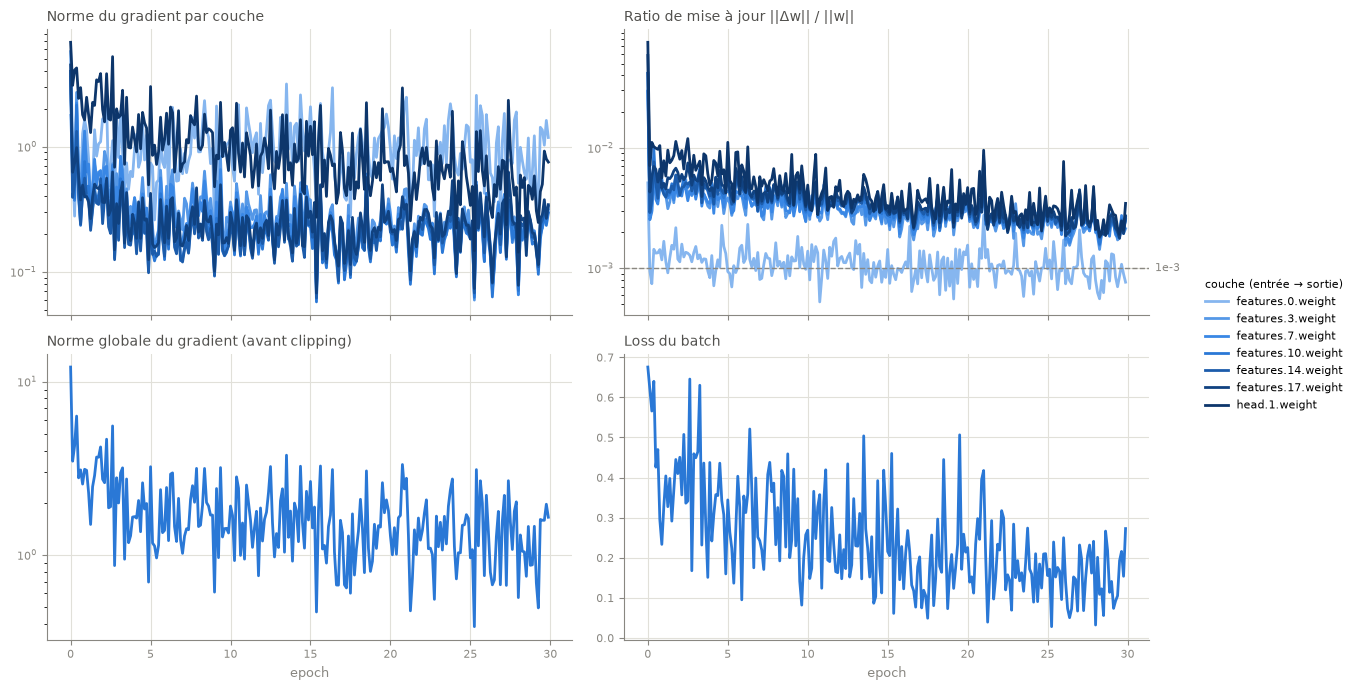

In [10]:
result["dynamics_figure"]

AUC ROC           : 0.9702
Précision Anomaly : 0.9465
Rappel Anomaly    : 0.8962


pred,No-Anomaly,Anomaly
true,,
No-Anomaly,1898,101
Anomaly,207,1788


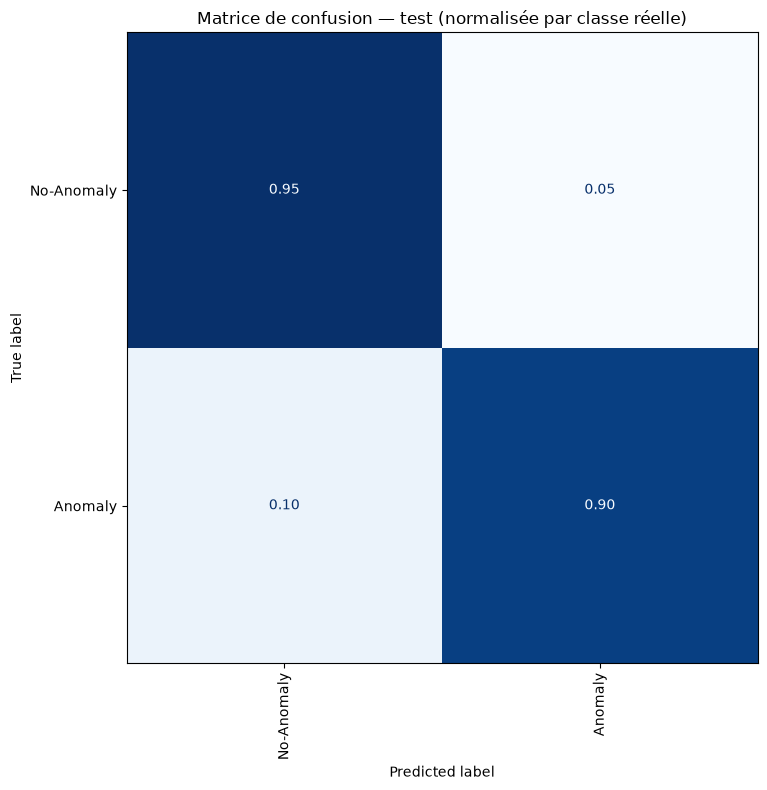

In [11]:
m = result["metrics"]
print(f"ROC AUC           : {result['roc_auc']['global']:.4f}")
print(f"Anomaly precision : {m['test_precision_Anomaly']:.4f}")
print(f"Anomaly recall    : {m['test_recall_Anomaly']:.4f}")

display(result["confusion_matrix"])
result["figure"]

In [12]:
preds = result["predictions"]
correct = preds[preds["correct"]]
errors = preds[~preds["correct"]]
print(f"Correct : {len(correct)} | Errors : {len(errors)}")

anomalies = preds[preds["label"] == "Anomaly"]
display(anomalies.groupby("label_orig")["correct"].agg(n="size", recall="mean")
        .sort_values("recall"))

display(errors.sort_values("confidence", ascending=False)
        [["filepath", "label_orig", "label", "pred_label", "confidence", "prob_true"]].head(15))

Bons : 3686 | Erreurs : 308


,n,rappel
label_orig,,
Offline-Module,165,0.642424
Hot-Spot,50,0.740000
Shadowing,209,0.741627
Hot-Spot-Multi,49,0.877551
Vegetation,328,0.905488
Diode-Multi,35,0.914286
Cell,375,0.949333
Diode,299,0.959866
Cell-Multi,257,0.968872


,filepath,label_orig,label,pred_label,confidence,prob_true
2643,d:\Computer Vision Engineer\infrared-solar\dat...,No-Anomaly,No-Anomaly,Anomaly,1.000000,4.581801e-09
982,d:\Computer Vision Engineer\infrared-solar\dat...,No-Anomaly,No-Anomaly,Anomaly,0.999997,3.302345e-06
1349,d:\Computer Vision Engineer\infrared-solar\dat...,No-Anomaly,No-Anomaly,Anomaly,0.999997,3.367520e-06
2717,d:\Computer Vision Engineer\infrared-solar\dat...,No-Anomaly,No-Anomaly,Anomaly,0.997917,2.082660e-03
2427,d:\Computer Vision Engineer\infrared-solar\dat...,No-Anomaly,No-Anomaly,Anomaly,0.997538,2.461595e-03
2619,d:\Computer Vision Engineer\infrared-solar\dat...,No-Anomaly,No-Anomaly,Anomaly,0.997364,2.635667e-03
2435,d:\Computer Vision Engineer\infrared-solar\dat...,No-Anomaly,No-Anomaly,Anomaly,0.997197,2.802784e-03
56,d:\Computer Vision Engineer\infrared-solar\dat...,No-Anomaly,No-Anomaly,Anomaly,0.997119,2.881016e-03
3933,d:\Computer Vision Engineer\infrared-solar\dat...,No-Anomaly,No-Anomaly,Anomaly,0.995864,4.135802e-03
1913,d:\Computer Vision Engineer\infrared-solar\dat...,No-Anomaly,No-Anomaly,Anomaly,0.995136,4.863700e-03


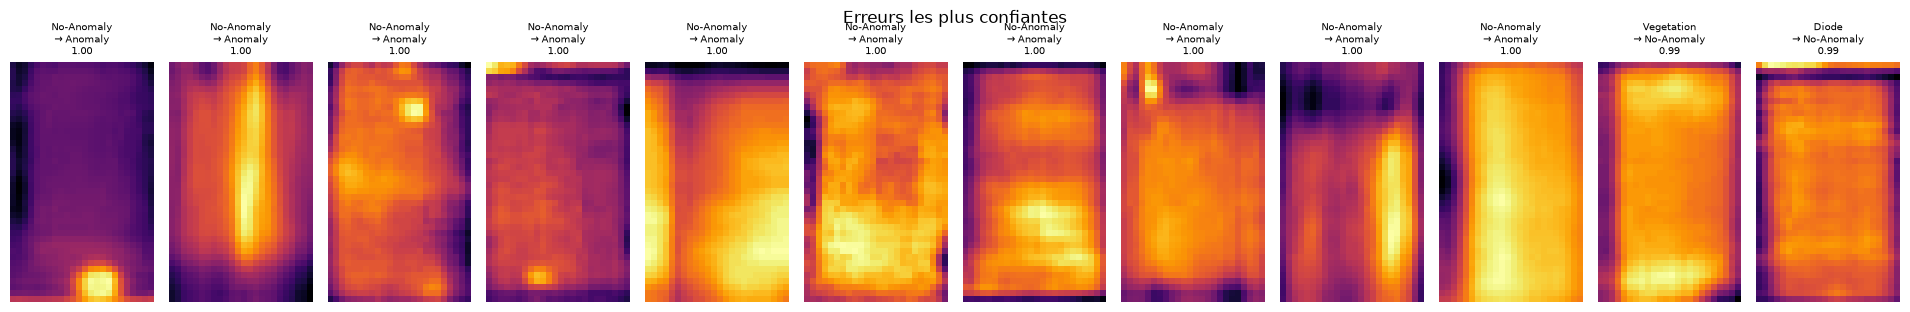

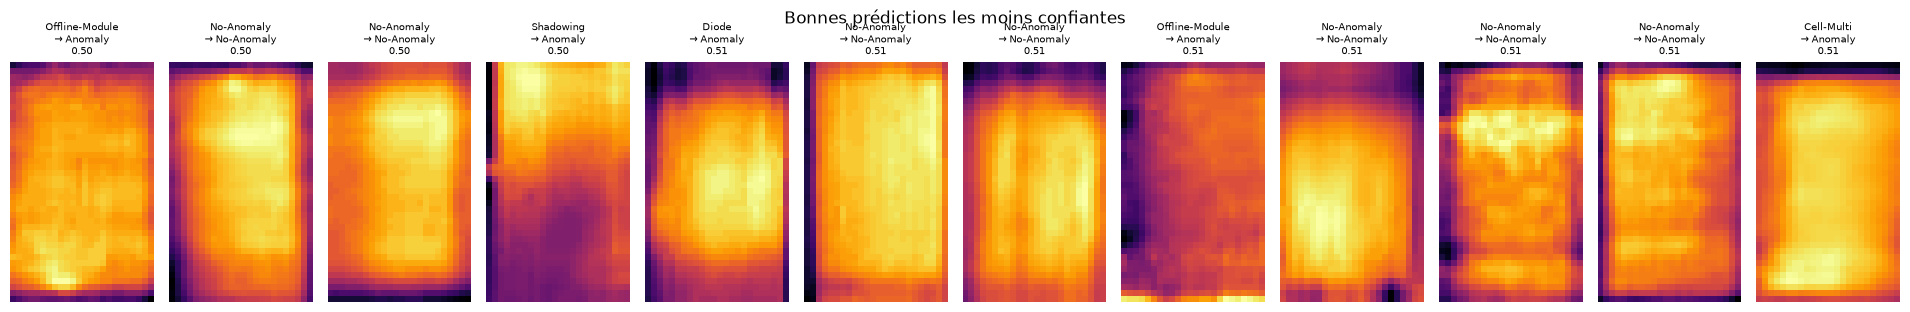

In [13]:
import matplotlib.pyplot as plt

def show_grid(df, n=12, title=""):
    df = df.head(n)
    fig, axes = plt.subplots(1, len(df), figsize=(1.6 * len(df), 3.2), squeeze=False)
    for ax, (_, r) in zip(axes[0], df.iterrows()):
        ax.imshow(Image.open(r["filepath"]).convert("L"), cmap="inferno")
        ax.set_title(f"{r['label_orig']}\n→ {r['pred_label']}\n{r['confidence']:.2f}", fontsize=7)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

show_grid(errors.sort_values("confidence", ascending=False), title="Most confident errors")
show_grid(correct.sort_values("confidence"), title="Least confident correct predictions")

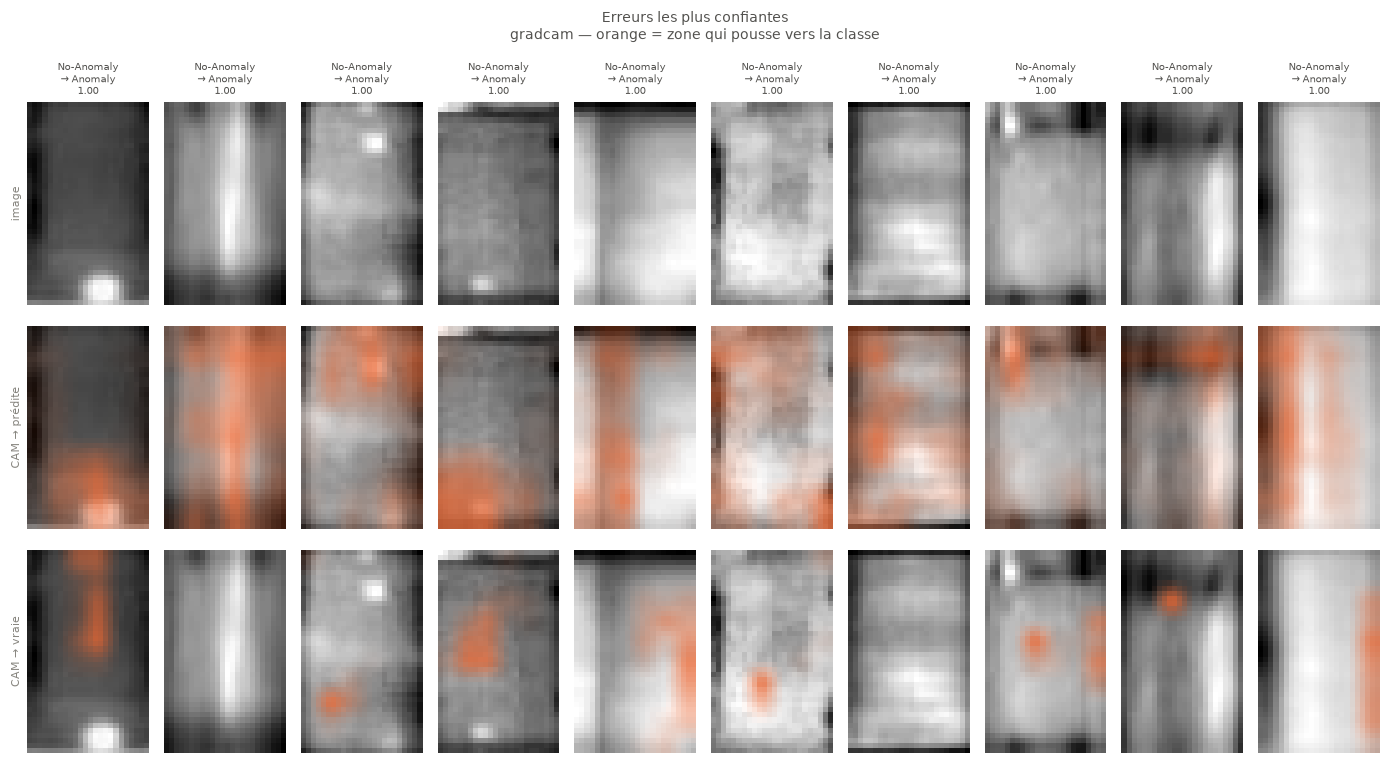

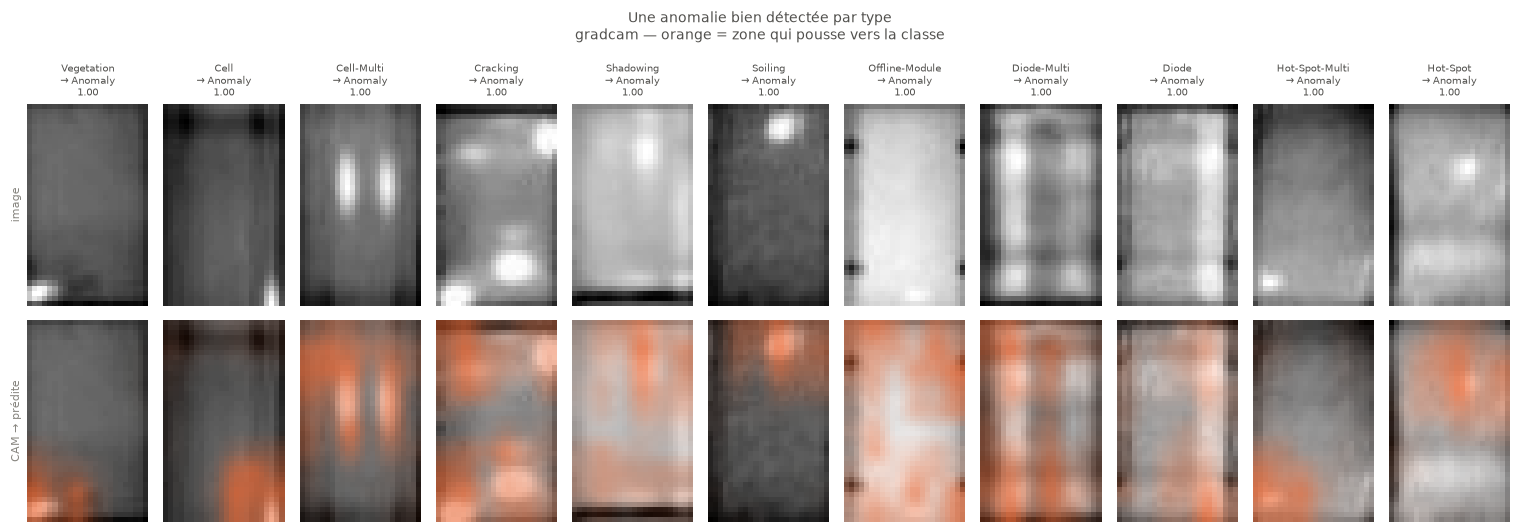

In [14]:
from explain import show_gradcam, extract_embeddings, embedding_map, plot_embedding_map, log_figures

TARGET_LAYER = model.features[19]
CAM_METHOD = "gradcam"

preds = result["predictions"]

confident_errors = preds[~preds["correct"]].nlargest(10, "confidence")
fig_cam_err = show_gradcam(model, dataset_test_with_label, confident_errors.index, TARGET_LAYER, classes,
                           targets=("pred", "true"), method=CAM_METHOD,
                           true_labels=confident_errors["label_orig"], title="Most confident errors")

best_per_type = (preds[preds["correct"] & (preds["label"] == "Anomaly")]
                 .sort_values("confidence", ascending=False).groupby("label_orig").head(1))
fig_cam_ok = show_gradcam(model, dataset_test_with_label, best_per_type.index, TARGET_LAYER, classes,
                          targets=("pred",), method=CAM_METHOD, true_labels=best_per_type["label_orig"],
                          title="One correctly detected anomaly per type")
display(fig_cam_err, fig_cam_ok)

d:\Computer Vision Engineer\infrared-solar\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


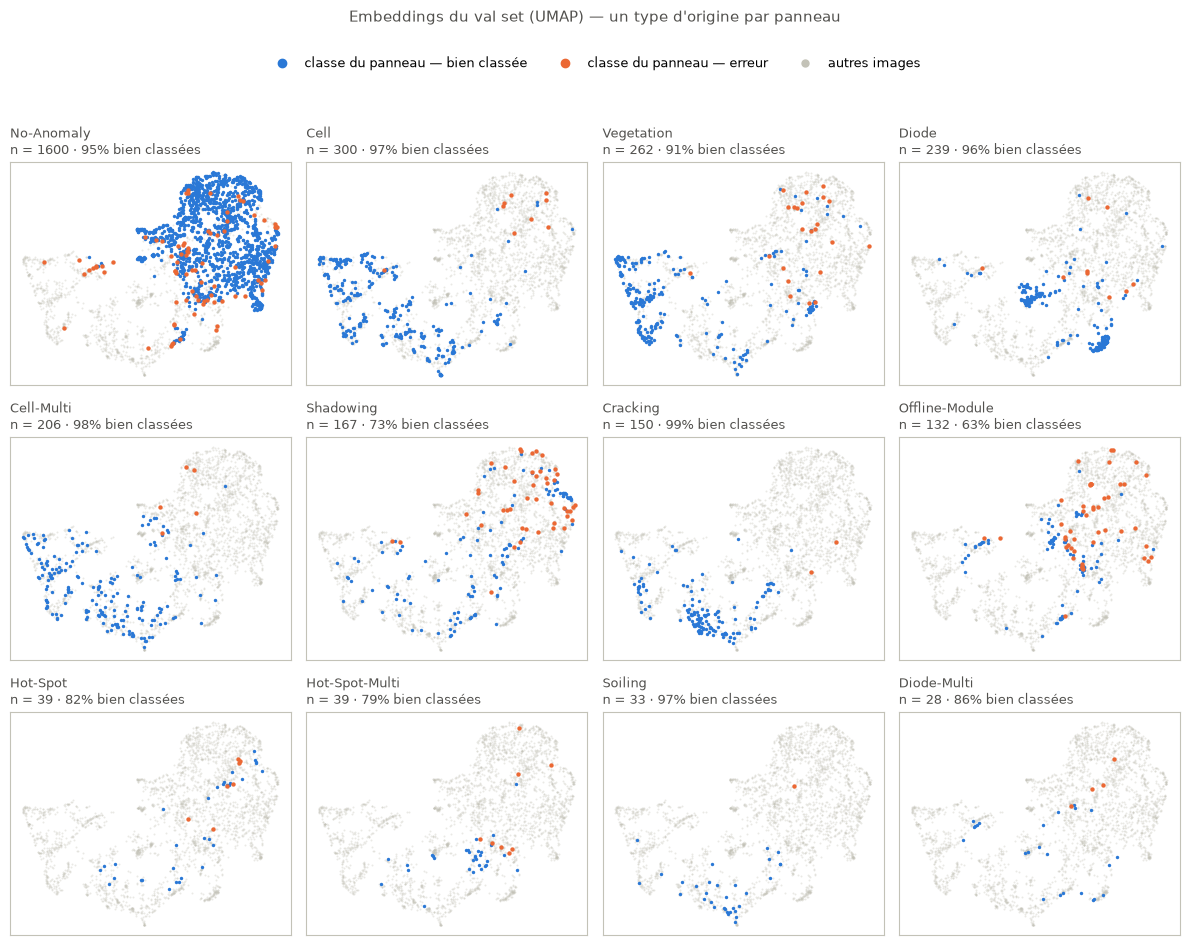

In [15]:
emb_val, y_val, y_val_pred = extract_embeddings(model, val_with_label_loader, model.pool)
xy_val = embedding_map(emb_val, method="umap")

fig_umap = plot_embedding_map(xy_val, groups=dataset_val_with_label.dataframe["label_orig"],
                              correct=y_val == y_val_pred,
                              title="Val set embeddings (UMAP), one original type per panel")
display(fig_umap)

log_figures(result["run_id"], {
    "explain/gradcam_errors.png": fig_cam_err,
    "explain/gradcam_correct.png": fig_cam_ok,
    "explain/umap_val.png": fig_umap,
})

In [16]:
print(compare_runs(EXPERIMENT_NAME).to_string(index=False))

                          run_id           tags.mlflow.runName  metrics.best_val_f1_macro  metrics.test_f1_macro  metrics.test_roc_auc  metrics.test_accuracy params.model params.lr params.num_epochs                       start_time
f808f9af2d344e3dae70e24a6952c16e simplecnn-binary-weighted-aug                   0.922334               0.924592              0.971272               0.924637    SimpleCNN     0.001                30 2026-10-07 17:16:59.734000+00:00
e3b730f6d7da4ca58cfe187e82ab38fb simplecnn-binary-weighted-aug                   0.923265               0.922826              0.970181               0.922884    SimpleCNN     0.001                30 2026-10-07 19:33:41.837000+00:00


## Label errors (cleanlab)

cleanlab flags images whose given label clearly contradicts the prediction of a model **that has never seen them**. The probabilities must therefore be *out-of-sample*: a model's predictions on its own training set are overfitted, because it has memorised the wrong labels and confirms them.

1. **Quick look** on the test set: the predictions of the run above are already out-of-sample.
2. **Full analysis**: 5-fold cross-validation over train + val + test (≈ 20,000 images). Each image is predicted by a model that has not seen it. Folds respect the similarity groups; otherwise a near-duplicate left in training would leak its label, even a wrong one.
3. **Review**: image grids, a CSV and a tag in FiftyOne. cleanlab proposes **candidates**, not verdicts: a label is only corrected after looking at the image.
4. **Optional**: retrain without the training-set suspects, keeping val and test untouched, and compare in MLflow.


Test : 116 labels suspects sur 3994


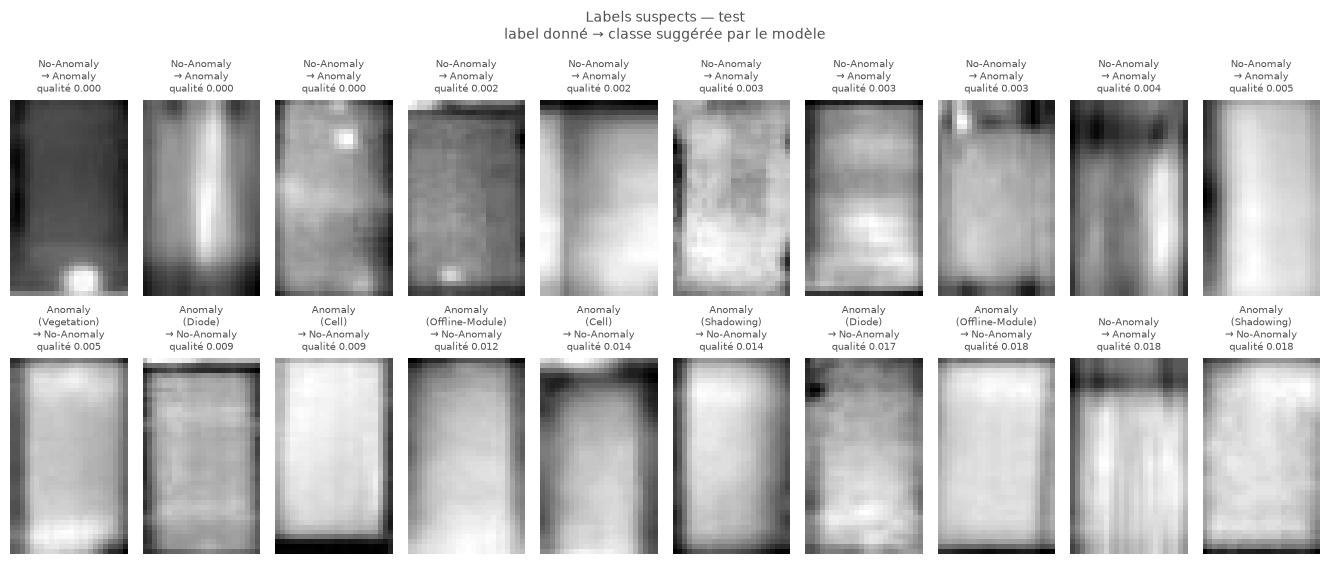

In [17]:
from label_issues import (cross_val_pred_probs, find_label_issues_df, label_noise_summary,
                          show_issues, log_label_issues, tag_fiftyone)

pp = result["predictions"]
issues_test = find_label_issues_df(pp["y_true"], pp[[f"prob_{c}" for c in classes]].values, classes, df=pp)
print(f"Test: {issues_test['is_label_issue'].sum()} suspected label issues out of {len(issues_test)}")
display(show_issues(issues_test[issues_test["is_label_issue"]], n=20, title="Suspected labels, test set"))

In [18]:
CV_FOLDS = 5
CV_EPOCHS = 20

all_df = pd.concat([train.assign(split="train"), val.assign(split="val"), test.assign(split="test")],
                   ignore_index=True)

def make_loader(df, train_mode):
    ds = CreateDataset(df, transform=train_transform if train_mode else eval_transform, label2idx=label2idx)
    return DataLoader(ds, batch_size=32 if train_mode else 256, shuffle=train_mode)

oof_probs, oof_folds = cross_val_pred_probs(
    all_df,
    make_model=lambda: SimpleCNN(n_classes=len(classes)),
    make_optimizer=lambda m: optim.Adam(m.parameters(), lr=0.001),
    criterion=criterion,
    make_loader=make_loader,
    n_splits=CV_FOLDS,
    num_epochs=CV_EPOCHS,
    stratify_col="label_orig",
    device=device,
)
oof_labels = all_df["label"].map(label2idx).values


===== Pli 1/5 : entraînement 15975 | prédit 3994 =====
Epoch [1/20] train_loss: 0.4621
Epoch [2/20] train_loss: 0.3644
Epoch [3/20] train_loss: 0.3353
Epoch [4/20] train_loss: 0.3147
Epoch [5/20] train_loss: 0.3044
Epoch [6/20] train_loss: 0.2885
Epoch [7/20] train_loss: 0.2799
Epoch [8/20] train_loss: 0.2679
Epoch [9/20] train_loss: 0.2631
Epoch [10/20] train_loss: 0.2569
Epoch [11/20] train_loss: 0.2456
Epoch [12/20] train_loss: 0.2498
Epoch [13/20] train_loss: 0.2316
Epoch [14/20] train_loss: 0.2239
Epoch [15/20] train_loss: 0.2250
Epoch [16/20] train_loss: 0.2202
Epoch [17/20] train_loss: 0.2073
Epoch [18/20] train_loss: 0.2102
Epoch [19/20] train_loss: 0.2072
Epoch [20/20] train_loss: 0.1972

===== Pli 2/5 : entraînement 15975 | prédit 3994 =====
Epoch [1/20] train_loss: 0.4682
Epoch [2/20] train_loss: 0.3639
Epoch [3/20] train_loss: 0.3354
Epoch [4/20] train_loss: 0.3110
Epoch [5/20] train_loss: 0.3065
Epoch [6/20] train_loss: 0.2914
Epoch [7/20] train_loss: 0.2796
Epoch [8/20] 

In [19]:
issues = find_label_issues_df(oof_labels, oof_probs, classes, df=all_df)
suspects = issues[issues["is_label_issue"]]
health, joint, per_class = label_noise_summary(oof_labels, oof_probs, classes)

print(f"Label health score: {health:.3f}  (1 = no estimated noise)")
print(f"Suspected labels: {len(suspects)} / {len(issues)} ({len(suspects) / len(issues):.1%})")

display(joint.round(4))

display(issues.groupby("split")["is_label_issue"].agg(n="size", suspects="sum", rate="mean"))
display(issues.groupby("label_orig")["is_label_issue"].agg(n="size", suspects="sum", rate="mean")
        .sort_values("rate", ascending=False))

Score de santé des labels : 0.975  (1 = aucun bruit estimé)
Labels suspects : 612 / 19969 (3.1%)


,vrai : No-Anomaly,vrai : Anomaly
donné : No-Anomaly,0.492,0.0087
donné : Anomaly,0.022,0.4774


,n,suspects,taux
split,,,
test,3994,129,0.032298
train,12780,398,0.031142
val,3195,85,0.026604


,n,suspects,taux
label_orig,,,
Offline-Module,821,142,0.172960
Hot-Spot,248,24,0.096774
Shadowing,1045,98,0.093780
Vegetation,1638,66,0.040293
Hot-Spot-Multi,246,9,0.036585
Cell,1876,46,0.024520
No-Anomaly,9997,173,0.017305
Cell-Multi,1287,22,0.017094
Soiling,204,3,0.014706


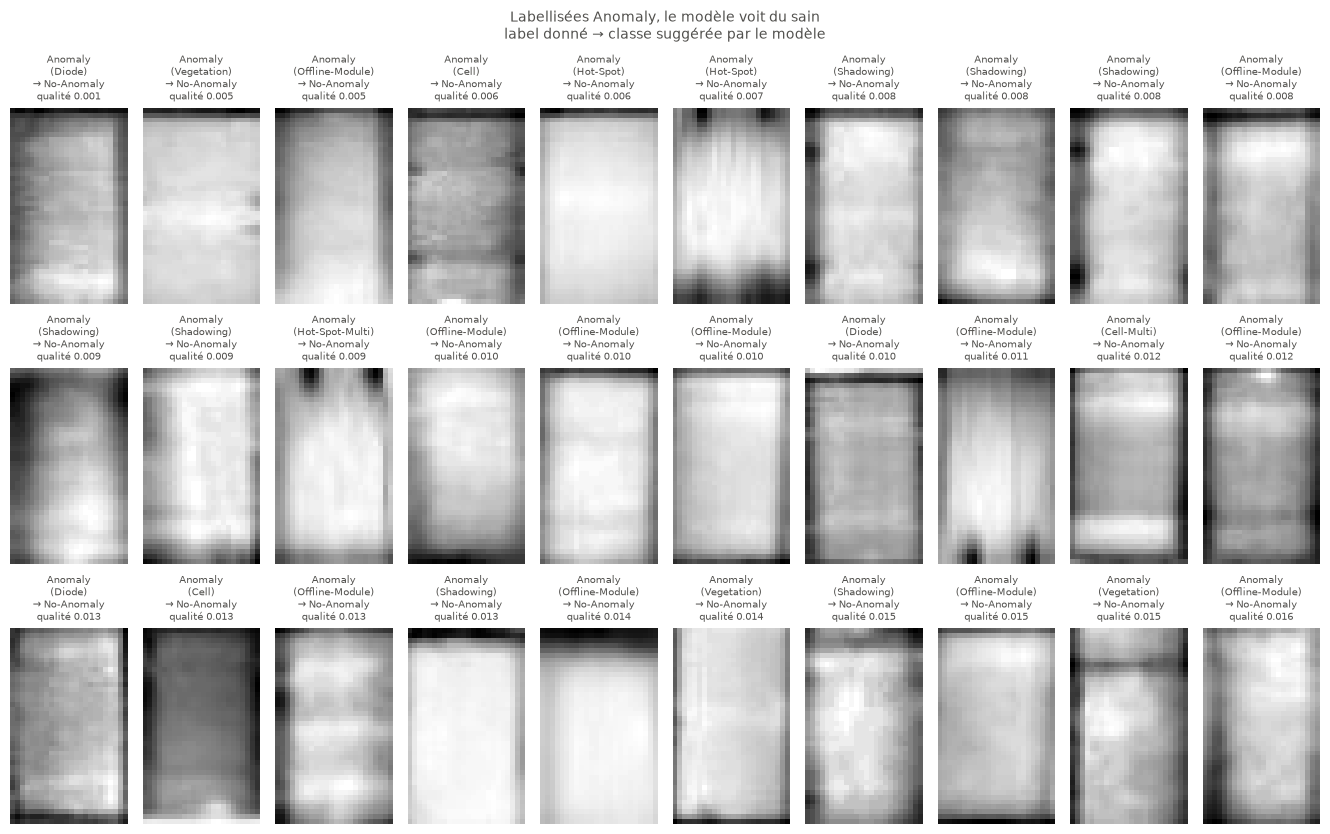

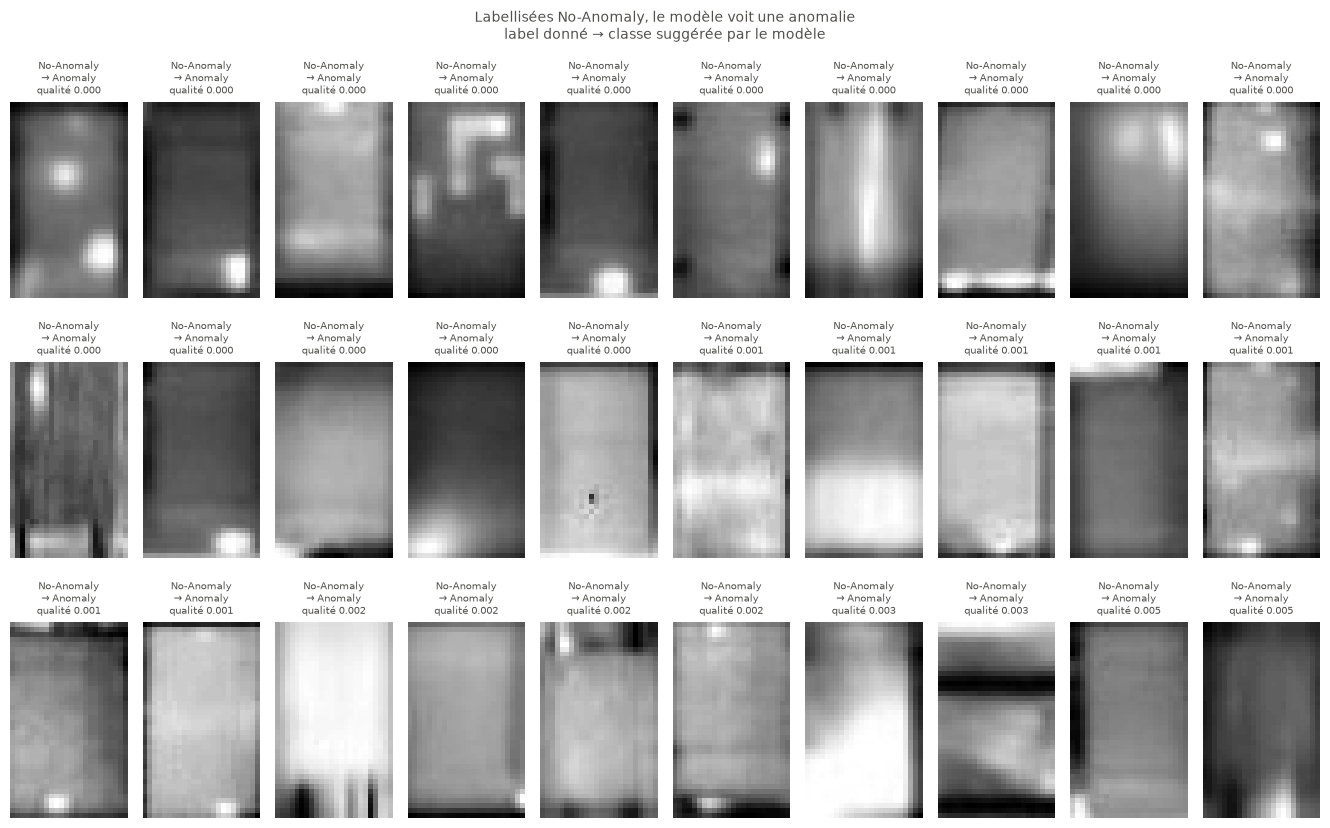

In [20]:
fig_given_anomaly = show_issues(suspects[suspects["given_label"] == "Anomaly"], n=30,
                                title="Labelled Anomaly, model sees a healthy module")
fig_given_normal = show_issues(suspects[suspects["given_label"] == "No-Anomaly"], n=30,
                               title="Labelled No-Anomaly, model sees an anomaly")
display(fig_given_anomaly, fig_given_normal)

In [21]:
cleanlab_run_id = log_label_issues(
    issues, oof_labels, oof_probs, classes,
    experiment_name="infrared-solar-label-issues",
    run_name=f"cleanlab-binary-simplecnn-cv{CV_FOLDS}",
    params={"task": "binary", "model": "SimpleCNN", "cv_folds": CV_FOLDS, "cv_epochs": CV_EPOCHS,
            "cv_groups": "similarity_group", "cv_stratify": "label_orig",
            "filter_by": "prune_by_noise_rate"},
    dataframe=all_df,
    figures={"cleanlab/given_anomaly.png": fig_given_anomaly,
             "cleanlab/given_no_anomaly.png": fig_given_normal},
)

suspects.to_csv(os.path.join(DATA_DIR, "label_issues_binary.csv"), index=False)

oof_accuracy           : 0.9167
oof_f1_macro           : 0.9167
oof_f1_weighted        : 0.9167
oof_roc_auc            : 0.9685
oof_precision_Anomaly  : 0.9321
oof_recall_Anomaly     : 0.8987

              precision    recall  f1-score   support

  No-Anomaly       0.90      0.93      0.92      9997
     Anomaly       0.93      0.90      0.92      9972

    accuracy                           0.92     19969
   macro avg       0.92      0.92      0.92     19969
weighted avg       0.92      0.92      0.92     19969


Run MLflow : 2af1a7c1336c45fc9c269dd1e14098b0


In [22]:
import fiftyone as fo

if fo.dataset_exists("InfraredSolar"):
    review = tag_fiftyone(issues)
    session = fo.launch_app(review, auto=False)
    print(f"{len(review)} suspects to review: {session.url}")
else:
    print("FiftyOne dataset 'InfraredSolar' not found: re-run the first cell of eda.ipynb.")

Dataset FiftyOne 'InfraredSolar' absent : relancer la 1re cellule de eda.ipynb.


In [23]:
suspects_train = set(suspects.loc[suspects["split"] == "train", "filepath"])
train_clean = train[~train["filepath"].isin(suspects_train)].reset_index(drop=True)
print(f"Train : {len(train)} -> {len(train_clean)} images ({len(suspects_train)} removed)")

clean_loader = DataLoader(CreateDataset(train_clean, transform=train_transform, label2idx=label2idx),
                          batch_size=32, shuffle=True)
counts_clean = train_clean["label"].map(label2idx).value_counts().sort_index()
criterion_clean = nn.CrossEntropyLoss(weight=torch.tensor(
    len(train_clean) / (len(classes) * counts_clean.values), dtype=torch.float32).to(device))
model_clean = SimpleCNN(n_classes=len(classes)).to(device)

result_clean = run_experiment(
    model_clean, criterion_clean, optim.Adam(model_clean.parameters(), lr=0.001),
    clean_loader, val_with_label_loader, test_with_label_loader,
    classes=classes,
    experiment_name=EXPERIMENT_NAME,
    run_name="simplecnn-binary-weighted-aug-cleanlab-pruned",
    num_epochs=30,
    device=device,
    params={
        "input_shape": "1x40x24",
        "dropout": 0.3,
        "class_weighting": "balanced",
        "augmentation": "hflip+vflip",
        "normalize": "mean=0.5, std=0.5",
        "cleanlab_pruned": len(suspects_train),
        "cleanlab_run_id": cleanlab_run_id,
    },
    tags={"dataset": "dataset_eda", "task": "binary", "stage": "cleanlab-pruned"},
)
print(compare_runs(EXPERIMENT_NAME).to_string(index=False))

Train : 12780 -> 12382 images (398 retirées)
Epoch [1/30] train_loss: 0.4514 | val_loss: 0.3817 | val_f1_macro: 0.8227  <- best
Epoch [2/30] train_loss: 0.3181 | val_loss: 0.3333 | val_f1_macro: 0.8547  <- best
Epoch [3/30] train_loss: 0.2858 | val_loss: 0.2894 | val_f1_macro: 0.8761  <- best
Epoch [4/30] train_loss: 0.2583 | val_loss: 0.3460 | val_f1_macro: 0.8623
Epoch [5/30] train_loss: 0.2352 | val_loss: 0.3127 | val_f1_macro: 0.8698
Epoch [6/30] train_loss: 0.2234 | val_loss: 0.2763 | val_f1_macro: 0.8851  <- best
Epoch [7/30] train_loss: 0.2153 | val_loss: 0.2668 | val_f1_macro: 0.8867  <- best
Epoch [8/30] train_loss: 0.2050 | val_loss: 0.3030 | val_f1_macro: 0.8803
Epoch [9/30] train_loss: 0.1957 | val_loss: 0.2699 | val_f1_macro: 0.8927  <- best
Epoch [10/30] train_loss: 0.1818 | val_loss: 0.3028 | val_f1_macro: 0.8745
Epoch [11/30] train_loss: 0.1833 | val_loss: 0.2691 | val_f1_macro: 0.8926
Epoch [12/30] train_loss: 0.1737 | val_loss: 0.2976 | val_f1_macro: 0.8916
Epoch [13/

2026/10/07 22:06:13 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/10/07 22:06:13 WARNING mlflow.utils.requirements_utils: Found torch version (2.7.1+cu118) contains a local version label (+cu118). MLflow logged a pip requirement for this package as 'torch==2.7.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/10/07 22:06:16 WARNING mlflow.utils.requirements_utils: Found torch version (2.7.1+cu118) contains a local version label (+cu118). MLflow logged a pip requirement for this package as 'torch==2.7.1' without the local version label 


Run MLflow : b53b37537fc042898ed73362210caf42
Visualiser : mlflow ui --backend-store-uri "sqlite:///D:/Computer Vision Engineer/infrared-solar/mlflow.db"
                          run_id                           tags.mlflow.runName  metrics.best_val_f1_macro  metrics.test_f1_macro  metrics.test_roc_auc  metrics.test_accuracy params.model params.lr params.num_epochs                       start_time
f808f9af2d344e3dae70e24a6952c16e                 simplecnn-binary-weighted-aug                   0.922334               0.924592              0.971272               0.924637    SimpleCNN     0.001                30 2026-10-07 17:16:59.734000+00:00
b53b37537fc042898ed73362210caf42 simplecnn-binary-weighted-aug-cleanlab-pruned                   0.921048               0.923301              0.968001               0.923385    SimpleCNN     0.001                30 2026-10-07 20:00:37.302000+00:00
e3b730f6d7da4ca58cfe187e82ab38fb                 simplecnn-binary-weighted-aug                   0.92